In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

In [2]:
PROJECT_DIR = Path.cwd()

RAW_FILE = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "World-Stock-Prices-Dataset.csv"
)

PROCESSED_DIR = (
    PROJECT_DIR
    / "data"
    / "processed"
)

PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [3]:
columns_to_use = [
    "Date",
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Ticker",
    "Industry_Tag"
]

stocks = pd.read_csv(
    RAW_FILE,
    usecols=columns_to_use
)

stocks["Date"] = (
    pd.to_datetime(
        stocks["Date"],
        utc=True
    )
    .dt.normalize()
)

stocks = (
    stocks
    .sort_values(["Ticker", "Date"])
    .drop_duplicates(
        subset=["Ticker", "Date"],
        keep="last"
    )
    .reset_index(drop=True)
)

print(stocks.shape)
stocks.head()

(306445, 8)


,Date,Open,High,Low,Close,Volume,Ticker,Industry_Tag
0,2000-01-03 00:00:00+00:00,0.794800,0.852586,0.770643,0.848323,535796800.0,AAPL,technology
1,2000-01-04 00:00:00+00:00,0.820377,0.838376,0.766854,0.776801,512377600.0,AAPL,technology
2,2000-01-05 00:00:00+00:00,0.786273,0.837902,0.780590,0.788168,778321600.0,AAPL,technology
3,2000-01-06 00:00:00+00:00,0.804273,0.810904,0.719961,0.719961,767972800.0,AAPL,technology
4,2000-01-07 00:00:00+00:00,0.731329,0.765433,0.723751,0.754065,460734400.0,AAPL,technology


In [4]:
stocks["Return_1d"] = (
    stocks
    .groupby("Ticker")["Close"]
    .pct_change(fill_method=None)
)

In [5]:
returns_wide = (
    stocks
    .pivot(
        index="Date",
        columns="Ticker",
        values="Return_1d"
    )
    .sort_index()
)

print(returns_wide.shape)
returns_wide.head()

(6408, 62)


Ticker,AAPL,ABNB,ADBE,ADDYY,AEO,AMD,AMZN,AXP,BAMXF,CL,...,TGT,TM,TSLA,TWTR,UBER,UBSFY,UL,V,ZI,ZM
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-03 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-04 00:00:00+00:00,-0.084310,NaN,-0.083890,NaN,-0.088068,-0.056452,-0.083217,-0.037758,NaN,-0.026104,...,-0.043365,-0.046332,NaN,NaN,NaN,NaN,-0.014553,NaN,NaN,NaN
2000-01-05 00:00:00+00:00,0.014633,NaN,0.019771,NaN,0.075545,0.025641,-0.148741,-0.025399,NaN,-0.034021,...,-0.022666,0.004049,NaN,NaN,NaN,NaN,0.042194,NaN,NaN,NaN
2000-01-06 00:00:00+00:00,-0.086538,NaN,0.008163,NaN,-0.070963,0.066667,-0.060036,0.020373,NaN,-0.002135,...,-0.047310,-0.088710,NaN,NaN,NaN,NaN,0.020243,NaN,NaN,NaN
2000-01-07 00:00:00+00:00,0.047369,NaN,0.048583,NaN,0.022603,0.015625,0.061010,0.014559,NaN,0.059893,...,0.051607,0.014749,NaN,NaN,NaN,NaN,0.055555,NaN,NaN,NaN


In [6]:
sector_wide = (
    stocks
    .groupby(
        ["Date", "Industry_Tag"]
    )["Return_1d"]
    .mean()
    .unstack("Industry_Tag")
    .sort_index()
)

sector_wide.head()

Industry_Tag,apparel,automotive,aviation,consumer goods,cryptocurrency,e-commerce,entertainment,finance,financial services,fitness,...,gaming,healthcare,hospitality,logistics,luxury goods,manufacturing,music,retail,social media,technology
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-03 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-04 00:00:00+00:00,-0.071307,-0.033075,-0.027559,-0.019967,NaN,-0.083217,0.058577,-0.029850,NaN,NaN,...,-0.059524,-0.036609,-0.006148,-0.033478,NaN,-0.039736,NaN,-0.047427,NaN,-0.043048
2000-01-05 00:00:00+00:00,0.066619,-0.008085,-0.004049,-0.003617,NaN,-0.148741,0.041502,-0.015786,NaN,NaN,...,-0.018987,0.010556,0.016495,0.022590,NaN,0.028966,NaN,-0.000753,NaN,0.013505
2000-01-06 00:00:00+00:00,-0.038079,-0.070150,-0.004065,0.021390,NaN,-0.060036,-0.039848,0.017285,NaN,NaN,...,-0.019355,0.031337,0.014198,0.113402,NaN,0.080429,NaN,-0.006499,NaN,-0.019694
2000-01-07 00:00:00+00:00,0.011302,0.025960,0.036735,0.065134,NaN,0.061010,-0.015810,0.016466,NaN,NaN,...,0.013158,0.042539,0.028000,0.005291,NaN,0.019851,NaN,0.044044,NaN,0.037068


In [7]:
selected_sectors = [
    "technology",
    "finance",
    "automotive",
    "retail",
    "food & beverage"
]

sector_plot_data = (
    sector_wide
    .loc["2015-01-01":, selected_sectors]
    .dropna()
)

In [8]:
cumulative_sector_return = (
    (1 + sector_plot_data)
    .cumprod()
    - 1
)

cumulative_sector_return.head()

Industry_Tag,technology,finance,automotive,retail,food & beverage
Date,,,,,
2015-01-02 00:00:00+00:00,-0.001092,0.002489,-0.007054,-0.009037,-0.003816
2015-01-05 00:00:00+00:00,-0.015958,-0.024501,-0.039106,-0.024936,-0.012514
2015-01-06 00:00:00+00:00,-0.030557,-0.038121,-0.035623,-0.024040,-0.011606
2015-01-07 00:00:00+00:00,-0.028234,-0.025540,-0.026408,0.006163,0.006419
2015-01-08 00:00:00+00:00,-0.008022,-0.009586,-0.010472,0.016209,0.022368


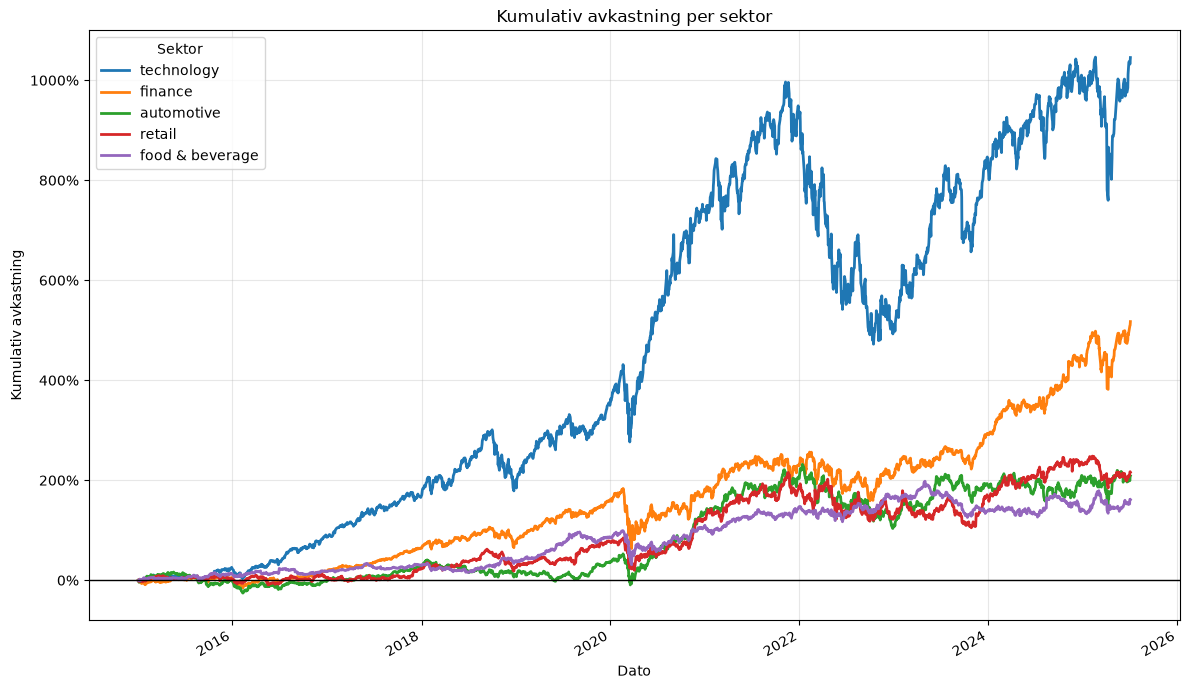

In [9]:
ax = cumulative_sector_return.plot(
    figsize=(12, 7),
    linewidth=2
)

ax.set_title(
    "Kumulativ avkastning per sektor"
)

ax.set_xlabel("Dato")
ax.set_ylabel("Kumulativ avkastning")

ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

ax.axhline(
    y=0,
    color="black",
    linewidth=1
)

ax.legend(
    title="Sektor"
)

ax.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [10]:
sector_wide.to_csv(
    PROCESSED_DIR
    / "sector_returns_wide.csv"
)